# Explore the Pushto Dictionary in Python
## 1,000 words, scripts, and sounds

A real, runnable notebook for [pushtodictionary.com](https://pushtodictionary.com) — a free trilingual Pashto dictionary with 126,000+ entries, Kandahari & Peshawari pronunciations, and English & Urdu meanings.

**The data:** `pushto-dictionary-1000-words.csv` in this repo — 1,000 Pashto words, each with the site's English gloss and a link to its live word page. The words come from the dictionary's own [Top 1000 Pashto Words](https://pushtodictionary.com/learn/top-1000-pashto-words) page (977 unique words), plus 6 phrase pages and 17 entries verified live through the site's own search API on 25 November 2026. Every row is a real word on the live site — nothing invented.

**Licence:** the sample is released under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) — use it, share it, credit pushtodictionary.com.

**Honest note:** romanization, Urdu gloss and part of speech are filled in wherever the site's own search API returned an exact verified match — the loader cell below prints the exact counts. Rows without them still carry the site's English gloss and the live link, which is what the source page publishes for them. The notebook says so wherever it matters, instead of guessing the missing fields.

In [1]:
# Load the 1,000-word sample.
# In Colab the CSV sits next to this notebook in the repo; if it is not
# found locally, fetch it from the repo's raw URL instead.
import os
import pandas as pd

CSV_FILE = "pushto-dictionary-1000-words.csv"
RAW_URL = ("https://raw.githubusercontent.com/Aziz0346/pushto-dictionary-notebooks"
           "/main/pushto-dictionary-1000-words.csv")

if os.path.exists(CSV_FILE):
    df = pd.read_csv(CSV_FILE)
    print(f"Loaded {CSV_FILE} (local file)")
else:
    df = pd.read_csv(RAW_URL)
    print(f"Loaded {RAW_URL}")

print(f"Rows: {len(df)}  |  Columns: {list(df.columns)}")
print(f"Unique Pashto words: {df['pashto'].nunique()}")
print(f"Rows with romanization: {df['romanization'].notna().sum()}  |  "
      f"with Urdu gloss: {df['urdu'].notna().sum()}  |  "
      f"with part of speech: {df['pos'].notna().sum()}")
df.head(8)

Loaded pushto-dictionary-1000-words.csv (local file)
Rows: 1000  |  Columns: ['pashto', 'romanization', 'english', 'urdu', 'pos', 'url', 'source']
Unique Pashto words: 1000
Rows with romanization: 795  |  with Urdu gloss: 779  |  with part of speech: 855


,pashto,romanization,english,urdu,pos,url,source
0,کول,kul,To do / to make,کرنا، بجا لانا، عمل کرنا,Noun (Masculine),https://pushtodictionary.com/word/کول,top-1000
1,کېدل,kedə́l,To become / to happen,ہونا، واقع ہونا، بننا,Verb,https://pushtodictionary.com/word/کېدل,top-1000
2,تلل,tləl,To go,جانا، روانہ ہونا، چلنا,Verb,https://pushtodictionary.com/word/تلل,top-1000
3,راتلل,rātlə́l,To come,آنا، تشریف لانا، پہنچنا,Verb,https://pushtodictionary.com/word/راتلل,top-1000
4,لیدل,lidə́l,To see / to watch,دیکھنا، دھیان، لحاظ,Verb,https://pushtodictionary.com/word/لیدل,top-1000
5,کتل,katə́l,To look / to view,نظر، آنکھ، گھڑی,Verb,https://pushtodictionary.com/word/کتل,top-1000
6,ویل,wayə́l,To say / to tell,بات، گپ,Verb,https://pushtodictionary.com/word/ویل,top-1000
7,خبرې کول,NaN,To speak / to talk,NaN,Noun,https://pushtodictionary.com/word/خبرې کول,top-1000


## Words by first letter

Pashto uses 44 letters. Which letters open the most words in this top-1000 sample?

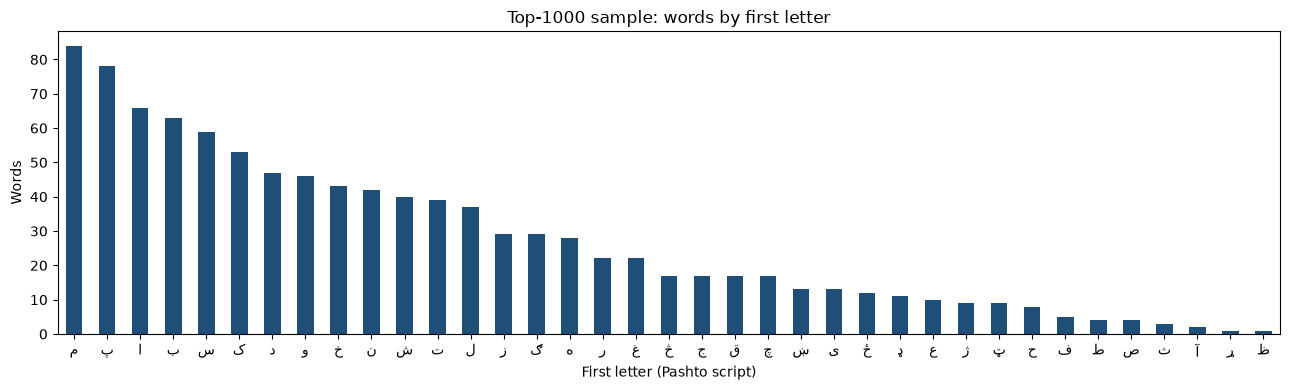

Distinct first letters in the sample: 37
Most common first letters:
first_letter
م    84
پ    78
ا    66
ب    63
س    59
ک    53
د    47
و    46
خ    43
ن    42


In [2]:
import matplotlib.pyplot as plt

df["first_letter"] = df["pashto"].str[0]
letter_counts = df["first_letter"].value_counts()

plt.figure(figsize=(13, 4))
letter_counts.plot(kind="bar", color="#1f4e79")
plt.title("Top-1000 sample: words by first letter")
plt.xlabel("First letter (Pashto script)")
plt.ylabel("Words")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(f"Distinct first letters in the sample: {df['first_letter'].nunique()}")
print("Most common first letters:")
print(letter_counts.head(10).to_string())

## How long are the words?

Word length in letters (Pashto script characters). Most everyday words are short — that is why the dictionary's top 1000 skews short.

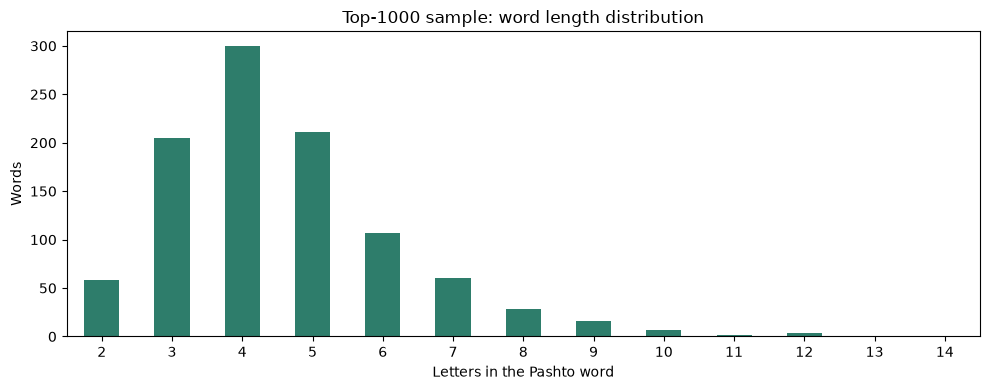

mean     4.583
50%      4.000
max     14.000

Shortest words: ['ښه', 'بد', 'یخ', 'آس', 'کب']
Longest words:  ['هیڅ خبره نه ده', 'ماښام مو پخير', 'په مخه مو ښه', 'د خدای پامان', 'سهار مو پخير']


In [3]:
df["length"] = df["pashto"].str.len()

plt.figure(figsize=(10, 4))
df["length"].value_counts().sort_index().plot(kind="bar", color="#2e7d6b")
plt.title("Top-1000 sample: word length distribution")
plt.xlabel("Letters in the Pashto word")
plt.ylabel("Words")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(df["length"].describe()[["mean", "50%", "max"]].to_string())
print(f"\nShortest words: {df.nsmallest(5, 'length')['pashto'].tolist()}")
print(f"Longest words:  {df.nlargest(5, 'length')['pashto'].tolist()}")

## Part of speech — a labelled subset

Only the rows that carry a part of speech are counted here (see the note at the top), so this is a **subset** table, not a claim about all 1,000 words.

In [4]:
pos_df = df[df["pos"].notna()]
print(f"Rows with a part of speech: {len(pos_df)} of {len(df)}")
print()
print(pos_df["pos"].value_counts().to_string())

Rows with a part of speech: 855 of 1000

pos
Noun (Masculine)      366
Noun (Feminine)       186
Noun                   89
Adjective              75
Verb                   61
Pronoun                22
Adverb                 19
Quantifier             17
Numeral                 7
Conjunction             3
Preposition             3
Proper Noun             2
Verb (Transitive)       1
Interjection            1
Particle                1
Postposition            1
Present Participle      1


## Search the sample

Type a word in Pashto script (`کتاب`) or in roman letters (`kitab`) — the search checks the Pashto word, the romanization, and the English gloss, and prints the live word page for every hit.

In [5]:
import unicodedata

def fold(text: str) -> str:
    """Lowercase and strip diacritics, so 'kitab' matches the API's 'kitā́b'."""
    if not isinstance(text, str):
        return ""
    decomposed = unicodedata.normalize("NFD", text.lower())
    return "".join(c for c in decomposed if unicodedata.category(c) != "Mn")

def search(query):
    """Search the 1,000-word sample by Pashto, romanization, or English gloss."""
    q = fold(query.strip())
    mask = (
        df["pashto"].str.contains(query.strip(), na=False)
        | df["romanization"].apply(lambda v: q in fold(v) if isinstance(v, str) else False)
        | df["english"].str.lower().str.contains(query.strip().lower(), na=False)
    )
    hits = df[mask]
    if hits.empty:
        print(f"No match for '{query}' in this 1,000-word sample.")
        print("Try the live search instead: "
              "https://pushtodictionary.com/api/v1/search?q=" + query)
        return hits
    for _, r in hits.iterrows():
        roman = f" / {r['romanization']}" if isinstance(r["romanization"], str) and r["romanization"] else ""
        print(f"{r['pashto']}{roman} — {r['english']}")
        print(f"  {r['url']}")
    return hits

print("--- search('kitab') ---")
search("kitab")
print("\n--- search('کتاب') ---")
search("کتاب")
print("\n--- search('book') ---")
search("book")

--- search('kitab') ---
کتاب / kitā́b — Book
  https://pushtodictionary.com/word/کتاب

--- search('کتاب') ---
کتاب / kitā́b — Book
  https://pushtodictionary.com/word/کتاب
کتابتون / kitaabtóon — Library
  https://pushtodictionary.com/word/کتابتون

--- search('book') ---
کتاب / kitā́b — Book
  https://pushtodictionary.com/word/کتاب
لارښود — Guide / handbook / advisor
  https://pushtodictionary.com/word/لارښود


,pashto,romanization,english,urdu,pos,url,source,first_letter,length
270,کتاب,kitā́b,Book,کتاب، تحریر شدہ نسخہ,Noun (Masculine),https://pushtodictionary.com/word/کتاب,top-1000,ک,4
315,لارښود,NaN,Guide / handbook / advisor,NaN,Noun,https://pushtodictionary.com/word/لارښود,top-1000,ل,6


## Why spelling matters: the two Yehs

Pashto is written with the **Farsi Yeh** `ی` (U+06CC). The **Arabic Yeh** `ي` (U+064A) looks almost identical but is a *different character* — a word typed with the wrong Yeh is a different URL. On 25 November 2026 the dictionary redirected both Arabic-Yeh test words to their Farsi spellings:

- `/word/ترويج` (Arabic Yeh) → **308 Permanent Redirect** to `/word/ترویج` (Farsi Yeh) → 200
- `/word/مینه` (Arabic Yeh) → **308 Permanent Redirect** to `/word/مینه` (Farsi Yeh) → 200

That is the dictionary enforcing its own spelling — and it is exactly why any Pashto text pipeline should normalise Yeh *before* looking a word up. The cell below proves it live; if the request fails (offline run), it prints the results recorded on 25 November 2026.

In [6]:
import urllib.request
import urllib.error

ARABIC_YEH = "\u064a"   # ي
FARSI_YEH = "\u06cc"    # ی

# Demo words built from explicit code points, so there is no doubt
# which Yeh each one carries:
#   tarwij = ت + ر + و + Yeh + ج   |   minah = م + Yeh + ن + ه
AR_TARWIJ = "ت\u0631\u0648" + ARABIC_YEH + "\u062c"   # Arabic Yeh
FA_TARWIJ = "ت\u0631\u0648" + FARSI_YEH + "\u062c"    # Farsi Yeh
AR_MINAH = "م" + ARABIC_YEH + "\u0646\u0647"           # Arabic Yeh
FA_MINAH = "م" + FARSI_YEH + "\u0646\u0647"            # Farsi Yeh

def normalise_yeh(word: str) -> str:
    """Replace Arabic Yeh with Farsi Yeh — the spelling the dictionary uses."""
    return word.replace(ARABIC_YEH, FARSI_YEH)

def check_word(word: str):
    """GET a word page without following redirects; report status + Location."""
    url = "https://pushtodictionary.com/word/" + urllib.parse.quote(word)
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    opener = urllib.request.build_opener(NoRedirectHandler)
    try:
        with opener.open(req, timeout=20) as r:
            return r.status, r.headers.get("Location")
    except urllib.error.HTTPError as e:
        return e.code, e.headers.get("Location")
    except Exception as e:
        return f"request failed ({e})", None

class NoRedirectHandler(urllib.request.HTTPRedirectHandler):
    def redirect_request(self, req, fp, code, msg, headers, newurl):
        return None

# Recorded on 25 Nov 2026 (used only if the live check cannot run):
RECORDED = {
    AR_TARWIJ: (308, "/word/" + FA_TARWIJ),
    FA_TARWIJ: (200, None),
    AR_MINAH: (308, "/word/" + FA_MINAH),
    FA_MINAH: (200, None),
}

for w in [AR_TARWIJ, FA_TARWIJ, AR_MINAH, FA_MINAH]:
    status, loc = check_word(w)
    if isinstance(status, str):  # request failed — fall back to the recorded result
        status, loc = RECORDED[w]
        print(f"{w}  ->  {status}  (recorded 25 Nov 2026; live check failed)")
    else:
        print(f"{w}  ->  {status}" + (f"  ->  {loc}" if loc else ""))
    print(f"    U+064A in word: {ARABIC_YEH in w}  |  normalised: {normalise_yeh(w)}")

print()
print("Rule: normalise Yeh before lookup — "
      "normalise_yeh('ترويج') == 'ترویج':", normalise_yeh("ترويج") == "ترویج")

ترويج  ->  308  ->  /word/%D8%AA%D8%B1%D9%88%DB%8C%D8%AC
    U+064A in word: True  |  normalised: ترویج


ترویج  ->  200
    U+064A in word: False  |  normalised: ترویج


مينه  ->  308  ->  /word/%D9%85%DB%8C%D9%86%D9%87
    U+064A in word: True  |  normalised: مینه


مینه  ->  200
    U+064A in word: False  |  normalised: مینه

Rule: normalise Yeh before lookup — normalise_yeh('ترويج') == 'ترویج': True


## Learn more

- **The dictionary:** [pushtodictionary.com](https://pushtodictionary.com)
- **Browse by topic:** [Learn Pashto](https://pushtodictionary.com/learn) — grammar guides, the Top 1000 list this sample came from, and phrase pages
- **Proverbs:** [Mataloona — Pashto proverbs](https://pushtodictionary.com/mataloona)
- **Word of the Day:** [pushtodictionary.com/word-of-the-day](https://pushtodictionary.com/word-of-the-day)
- **Try the live search API** (no key needed — this is how 17 rows of this sample were verified): `https://pushtodictionary.com/api/v1/search?q=کتاب` returns the entry with romanization, part of speech, and English + Urdu glosses.

Built 25 November 2026. Sample: 1,000 words, CC BY 4.0, source links in every row.